Data discovery and preparation

Walk the folders, clean the images, encode the labels, split the dataset and build fast tf.data pipelines. The reusable code lives in src/neurovision/data.py.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

sys.path.insert(0, os.path.abspath("../src"))

from neurovision import data

ROOT = os.path.abspath("../Data/raw")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print(ROOT)
print("classes   :", data.CLASSES)
print("image size:", IMG_SIZE)

/home/kcrowly/PycharmProjects/NeuroVision/Data/raw
classes   : ('glioma', 'meningioma', 'notumor', 'pituitary')
image size: (224, 224)


Walking the folders

One folder per class. Files with an extension other than jpeg, jpg, bmp or png are rejected and reported with a reason.

In [2]:
paths, labels, rejected = data.list_image_files(ROOT)

print(f"kept     : {len(paths)}")
print(f"rejected : {len(rejected)}")

for path, reason in rejected[:10]:
    print("   ", os.path.basename(path), "->", reason)

kept     : 7023
rejected : 0


Loading the images

Each image is read with OpenCV and resized to 224x224 with 3 channels. A corrupt file is caught and skipped so one bad image cannot stop the load.

In [3]:
images, labels, failed = data.load_images(ROOT)

print("shape :", images.shape)
print("dtype :", images.dtype)
print("failed:", len(failed))

for path, error in failed[:10]:
    print("   ", os.path.basename(path), "->", error)

shape : (7023, 224, 224, 3)
dtype : uint8
failed: 0


Shuffling images and labels

One permutation is applied to both arrays so an image and its label always stay together.

In [4]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(images))
images, labels = images[order], labels[order]

assert images.shape[0] == labels.shape[0]
print("labels :", labels[:20])
print("counts:", np.bincount(labels, minlength=data.NUM_CLASSES))

labels : [1 2 3 2 3 0 3 1 0 1 0 1 1 1 1 1 0 2 1 1]
counts: [1621 1645 2000 1757]


Labels and MobileNetV2 preprocessing

Each class becomes an integer index. MobileNetV2 expects pixels in [-1, 1], so the images are scaled with preprocess_input before training.

In [5]:
for name, index in data.LABEL_TO_INDEX.items():
    print(f"{index} -> {name}")

# One-hot form, used with categorical cross-entropy instead of sparse.
print("one-hot sample:")
print(data.one_hot(labels[:3]))

# MobileNetV2 preprocessing: [0, 255] becomes [-1, 1].
raw = tf.io.decode_image(tf.io.read_file(paths[0]), channels=3)
sample = tf.cast(raw, tf.float32)
scaled = tf.keras.applications.mobilenet_v2.preprocess_input(sample)

print("before:", float(sample.numpy().min()), float(sample.numpy().max()))
print("after :", float(scaled.numpy().min()), float(scaled.numpy().max()))

0 -> glioma
1 -> meningioma
2 -> notumor
3 -> pituitary
one-hot sample:
[[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


before: 0.0 255.0
after : -1.0 1.0


Splitting the dataset

Stratified split, so train, validation and test keep the same class proportions.

In [6]:
splits = data.split_paths(paths, labels, val_split=0.15, test_split=0.15, seed=SEED)

for name, (split_paths, split_labels) in splits.items():
    if split_paths is None:
        continue
    counts = {data.CLASSES[i]: int((split_labels == i).sum())
              for i in range(data.NUM_CLASSES)}
    print(f"{name:6s} {len(split_paths):5d}  {counts}")

train   4916  {'glioma': 1135, 'meningioma': 1151, 'notumor': 1400, 'pituitary': 1230}
val     1053  {'glioma': 243, 'meningioma': 247, 'notumor': 300, 'pituitary': 263}
test    1054  {'glioma': 243, 'meningioma': 247, 'notumor': 300, 'pituitary': 264}


tf.data pipelines

Images are decoded and resized on the fly instead of being held in memory. Augmentation is applied to the training set only.

In [7]:
train_ds = data.build_dataset(*splits["train"], batch_size=BATCH_SIZE, shuffle=True,
                              seed=SEED, cache=False,
                              augmentation=data.make_augmentation(seed=SEED),
                              preprocess="mobilenet")
val_ds = data.build_dataset(*splits["val"], batch_size=BATCH_SIZE, cache=False,
                            preprocess="mobilenet")
test_ds = data.build_dataset(*splits["test"], batch_size=BATCH_SIZE, cache=False,
                             preprocess="mobilenet")

for name, dataset in (("train", train_ds), ("val", val_ds), ("test", test_ds)):
    batch_images, batch_labels = next(iter(dataset))
    print(f"{name:6s} {str(batch_images.shape):22s} pixels {float(batch_images.numpy().min()):+.1f} to {float(batch_images.numpy().max()):+.1f}")

train  (32, 224, 224, 3)      pixels -1.0 to +1.0
val    (32, 224, 224, 3)      pixels -1.0 to +1.0
test   (32, 224, 224, 3)      pixels -1.0 to +1.0


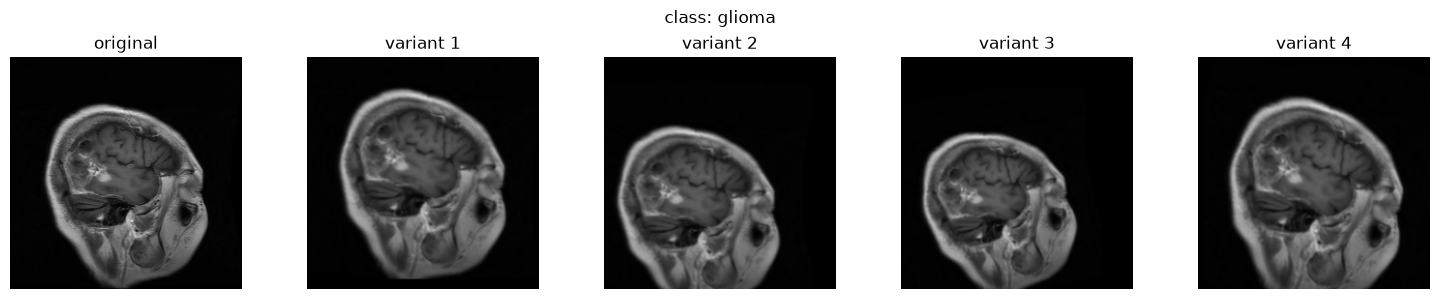

In [8]:
# Augmentation suited to MRI: light rotations, zoom and shifts.
# No horizontal flip, it would swap the left and right of the brain.
augmentation = data.make_augmentation(seed=SEED)
sample, sample_label = data.decode_image(splits["train"][0][0],
                                        int(splits["train"][1][0]))

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(sample.numpy())
axes[0].set_title("original")

for index in range(1, 5):
    variant = augmentation(tf.expand_dims(sample, 0), training=True)[0]
    axes[index].imshow(variant.numpy().astype("uint8"))
    axes[index].set_title(f"variant {index}")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"class: {data.CLASSES[sample_label]}")
plt.tight_layout()
plt.show()

Class distribution

The ratio between the largest and the smallest class tells us whether rebalancing is needed.

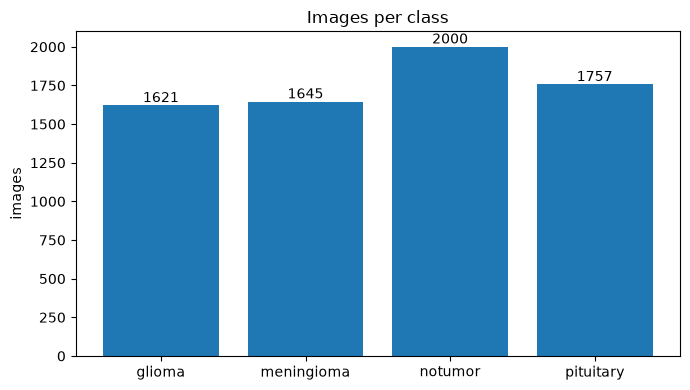

glioma       1621   23.1 %
meningioma   1645   23.4 %
notumor      2000   28.5 %
pituitary    1757   25.0 %
ratio max/min : 1.234
rebalance     : False


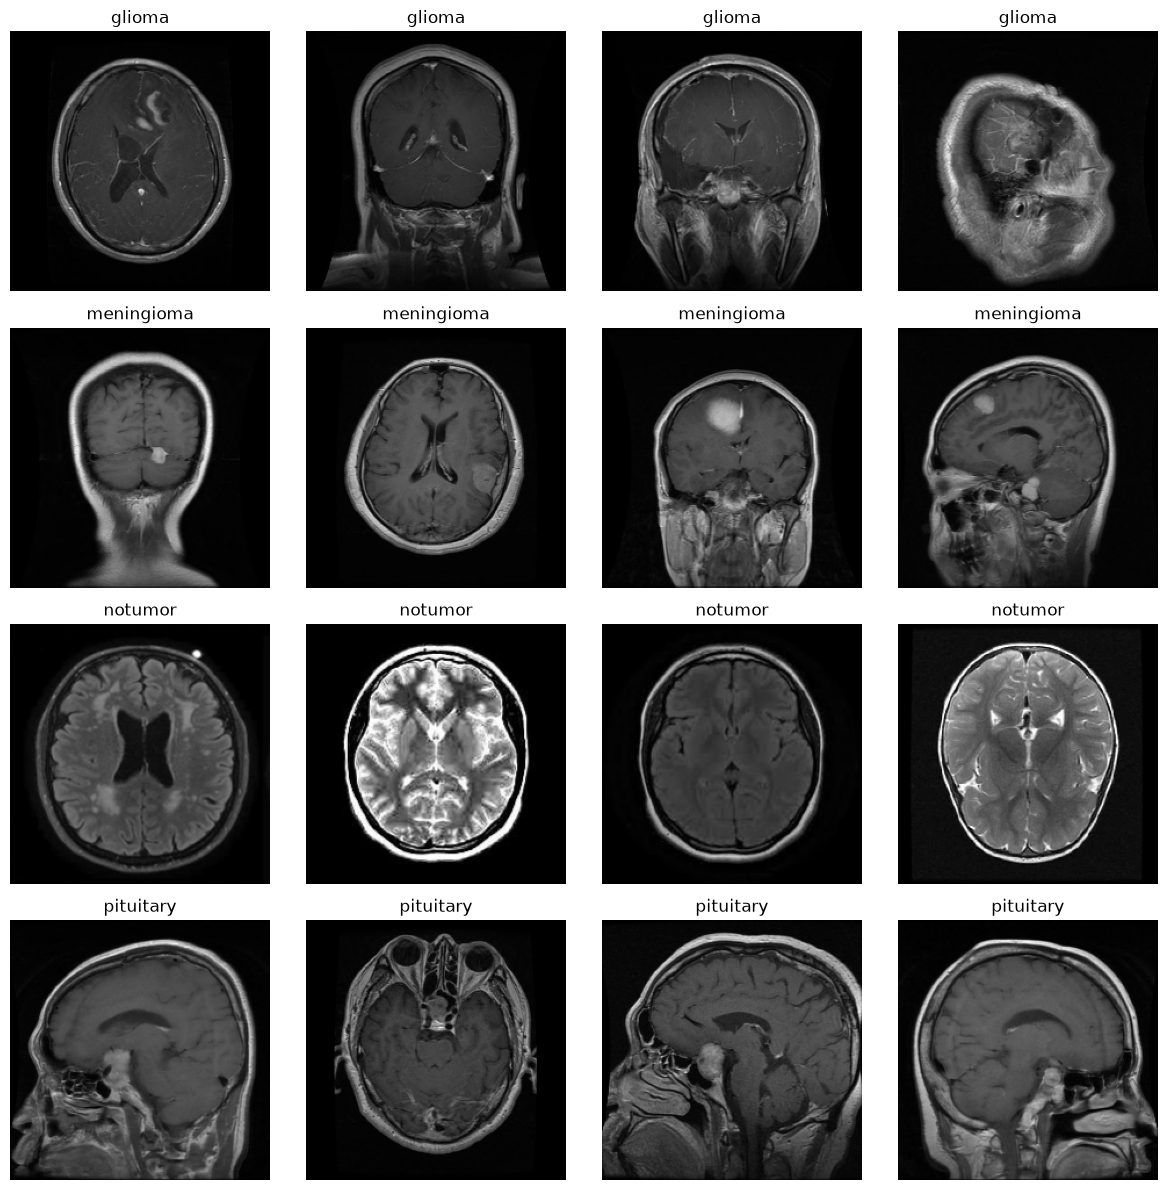

In [9]:
counts, ratio, needs_rebalancing = data.class_balance(ROOT)
data.plot_class_distribution(ROOT)

total = sum(counts.values())
for name, number in counts.items():
    print(f"{name:11s} {number:5d}  {number / total * 100:5.1f} %")

print(f"ratio max/min : {ratio:.3f}")
print(f"rebalance     : {needs_rebalancing}")

data.show_examples(ROOT, per_class=4)

Conclusion

7023 MRI across four classes, all loaded as 224x224x3 with no corrupt file. Images and labels stay aligned after the shuffle. Classes range from 1621 to 2000 images, a ratio of 1.23, so rebalancing is not needed.

The tf.data pipelines are ready: train, validation and test are split in a stratified way, pixels are in [-1, 1] for MobileNetV2, and augmentation is applied to the training set only.